In [1]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

import os
os.chdir('/content/drive/MyDrive/ve/variance_analysis')

Mounted at /content/drive/


In [2]:
!pip install -e /content/drive/MyDrive/ve/variance_analysis

Obtaining file:///content/drive/MyDrive/ve/variance_analysis
  Preparing metadata (setup.py) ... done
  Running setup.py develop for variance_analysis


In [3]:
!pip -q install fonttools

!ttx -l fonts/Helvetica.ttc

!sudo mkdir -p /usr/share/fonts/truetype/helvetica
!ttx -y 0 -o /usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf fonts/Helvetica.ttc
!ttx -y 1 -o /usr/share/fonts/truetype/helvetica/Helvetica-Oblique.ttf fonts/Helvetica.ttc
!ttx -y 2 -o /usr/share/fonts/truetype/helvetica/Helvetica-Bold.ttf fonts/Helvetica.ttc
!ttx -y 3 -o /usr/share/fonts/truetype/helvetica/Helvetica-BoldOblique.ttf fonts/Helvetica.ttc

!fc-cache -fv


ERROR: specify a font number between 0 and 5 (inclusive)
Dumping "fonts/Helvetica.ttc" to "/usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf"...
Dumping 'GlyphOrder' table...
Dumping 'head' table...
Dumping 'hhea' table...
Dumping 'maxp' table...
Dumping 'OS/2' table...
Dumping 'hmtx' table...
Dumping 'hdmx' table...
Dumping 'cmap' table...
Dumping 'fpgm' table...
Dumping 'prep' table...
Dumping 'cvt ' table...
Dumping 'loca' table...
Dumping 'glyf' table...
Dumping 'kern' table...
Dumping 'name' table...
Dumping 'post' table...
Dumping 'Zapf' table...
Dumping 'feat' table...
Dumping 'meta' table...
Dumping 'morx' table...
Dumping 'prop' table...
Dumping "fonts/Helvetica.ttc" to "/usr/share/fonts/truetype/helvetica/Helvetica-Oblique.ttf"...
Dumping 'GlyphOrder' table...
Dumping 'head' table...
Dumping 'hhea' table...
Dumping 'maxp' table...
Dumping 'OS/2' table...
Dumping 'hmtx' table...
Dumping 'cmap' table...
Dumping 'fpgm' table...
Dumping 'prep' table...
Dumping 'cvt ' tabl

# GLM

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.font_manager as fm
import shutil

from pathlib import Path
current_file_path = Path().resolve()
current_file_path

!mkdir -p ~/.fonts
!cp fonts/Helvetica.ttc ~/.fonts/

cache_dir = os.path.join(os.path.expanduser("~"), ".cache", "matplotlib")
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

fm._load_fontmanager(try_read_cache=False)
plt.rcParams['font.family'] = 'Helvetica'

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

rng = np.random.default_rng(0)
n = 20000
x = rng.normal(0, 1.0, size=n)
y = rng.normal(0, 1.0, size=n)

def rotated_coord(x, y, c, theta, wrap=False):
    if wrap:
        d1 = ((x - c + 0.5) % 1.0) - 0.5
        d2 = ((y - c + 0.5) % 1.0) - 0.5
    else:
        d1 = x - c
        d2 = y - c
    ct, st = np.cos(theta), np.sin(theta)
    u = d1 * ct - d2 * st
    return u

mu = 0.0
theta = 60
theta_r = np.deg2rad(theta)
sigma_u = 1.2

u = rotated_coord(x, y, mu, theta_r, wrap=False)

alpha = np.log(5.0)
eta = alpha - ((u - mu) ** 2) / (2 * sigma_u ** 2)
lam = np.exp(eta)
spikes = rng.poisson(lam)
df = pd.DataFrame(dict(x=x, y=y, spikes=spikes))

In [10]:
modelA = smf.glm("spikes ~ x + y + I(x**2) + I(y**2)", data=df, family=sm.families.Poisson()).fit()
print(modelA.summary())

def pseudo_r2(counts, mu):
    def ll(y, m):
        m = np.clip(m, 1e-12, None)
        return np.sum(y * np.log(m) - m)
    mu_null = np.full_like(counts, np.mean(counts))
    return 1.0 - ll(counts, mu) / ll(counts, mu_null)

muA = modelA.fittedvalues.values
print(f"\\nMcFadden pseudo-R^2 (Model A): {pseudo_r2(spikes, muA):.3f}")

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 spikes   No. Observations:                20000
Model:                            GLM   Df Residuals:                    19995
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -42177.
Date:                Sun, 28 Dec 2025   Deviance:                       25256.
Time:                        16:33:45   Pearson chi2:                 2.42e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2349
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.5850      0.005    310.121      0.0

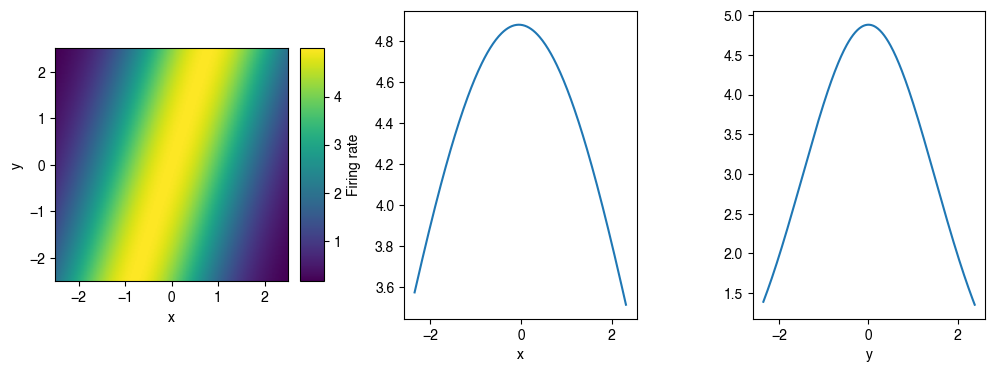

In [11]:
grid = np.linspace(-2.5, 2.5, 160)
Xg, Yg = np.meshgrid(grid, grid)
Ug = rotated_coord(Xg, Yg, mu, theta, wrap=False)
eta_true_grid = alpha - ((Ug - mu) ** 2) / (2 * sigma_u ** 2)
lam_true_grid = np.exp(eta_true_grid)

x_grid = np.linspace(np.percentile(x, 1), np.percentile(x, 99), 300)
y_grid = np.linspace(np.percentile(y, 1), np.percentile(y, 99), 300)
x_mean = float(np.mean(x))
y_mean = float(np.mean(y))

df_x = pd.DataFrame({
    "x": x_grid,
    "y": y_mean,
    "x2": x_grid**2,
    "y2": np.full_like(x_grid, y_mean**2),
})
pred_x = modelA.predict(df_x[["x","y","x2","y2"]]).to_numpy()

df_y = pd.DataFrame({
    "x": x_mean,
    "y": y_grid,
    "x2": np.full_like(y_grid, x_mean**2),
    "y2": y_grid**2,
})
pred_y = modelA.predict(df_y[["x","y","x2","y2"]]).to_numpy()

fig = plt.figure(figsize=(12, 4))

ax1 = plt.subplot(1, 3, 1)
ax1.set_aspect('equal')
im = ax1.imshow(lam_true_grid, origin="lower",
                extent=[grid.min(), grid.max(), grid.min(), grid.max()])
ax1.set_xlabel("x"); ax1.set_ylabel("y")

ax2 = plt.subplot(1, 3, 2)
ax2.plot(x_grid, pred_x)
ax2.set_xlabel("x")

ax3 = plt.subplot(1, 3, 3)
ax3.plot(y_grid, pred_y)
ax3.set_xlabel("y")

plt.subplots_adjust(wspace=0.5)
cbar_ax = fig.add_axes([ax1.get_position().x1 + 0.01,
                        ax1.get_position().y0,
                        0.02,
                        ax1.get_position().height])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Firing rate")
plt.savefig(current_file_path / f'figs/glm_theta_{theta}.pdf')

plt.show()

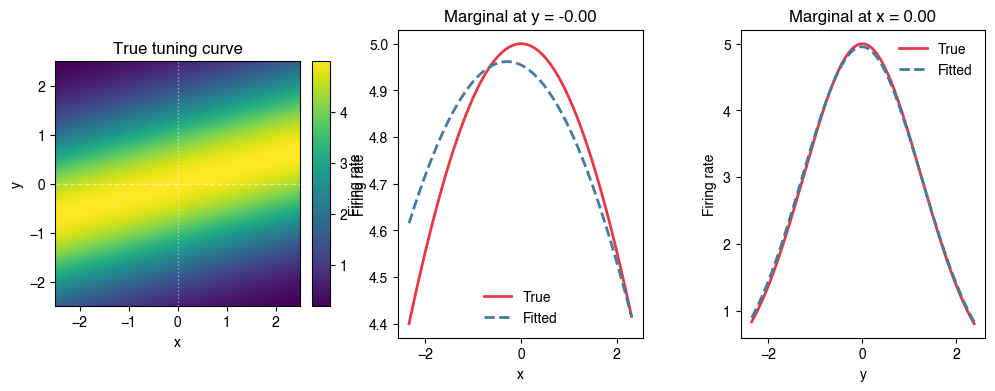

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set up the simulation
rng = np.random.default_rng(0)
n = 20000
x = rng.normal(0, 1.0, size=n)
y = rng.normal(0, 1.0, size=n)

def rotated_coord(x, y, c, theta, wrap=False):
    if wrap:
        d1 = ((x - c + 0.5) % 1.0) - 0.5
        d2 = ((y - c + 0.5) % 1.0) - 0.5
    else:
        d1 = x - c
        d2 = y - c
    ct, st = np.cos(theta), np.sin(theta)
    u = d1 * ct - d2 * st
    return u

mu = 0.0
theta = 75
theta_r = np.deg2rad(theta)
sigma_u = 1.2

u = rotated_coord(x, y, mu, theta_r, wrap=False)

alpha = np.log(5.0)
eta = alpha - ((u - mu) ** 2) / (2 * sigma_u ** 2)
lam = np.exp(eta)
spikes = rng.poisson(lam)
df = pd.DataFrame(dict(x=x, y=y, spikes=spikes))

# Fit the model
modelA = smf.glm("spikes ~ x + y + I(x**2) + I(y**2)", data=df, family=sm.families.Poisson()).fit()

# Create grids for visualization
grid = np.linspace(-2.5, 2.5, 160)
Xg, Yg = np.meshgrid(grid, grid)
Ug = rotated_coord(Xg, Yg, mu, theta_r, wrap=False)
eta_true_grid = alpha - ((Ug - mu) ** 2) / (2 * sigma_u ** 2)
lam_true_grid = np.exp(eta_true_grid)

x_grid = np.linspace(np.percentile(x, 1), np.percentile(x, 99), 300)
y_grid = np.linspace(np.percentile(y, 1), np.percentile(y, 99), 300)
x_mean = float(np.mean(x))
y_mean = float(np.mean(y))

# Fitted marginals
df_x = pd.DataFrame({"x": x_grid, "y": y_mean, "x2": x_grid**2, "y2": np.full_like(x_grid, y_mean**2)})
pred_x = modelA.predict(df_x[["x","y","x2","y2"]]).to_numpy()

df_y = pd.DataFrame({"x": x_mean, "y": y_grid, "x2": np.full_like(y_grid, x_mean**2), "y2": y_grid**2})
pred_y = modelA.predict(df_y[["x","y","x2","y2"]]).to_numpy()

# TRUE marginals (evaluated at the mean of the other variable)
u_true_x = rotated_coord(x_grid, np.full_like(x_grid, y_mean), mu, theta_r, wrap=False)
eta_true_x = alpha - ((u_true_x - mu) ** 2) / (2 * sigma_u ** 2)
lam_true_x = np.exp(eta_true_x)

u_true_y = rotated_coord(np.full_like(y_grid, x_mean), y_grid, mu, theta_r, wrap=False)
eta_true_y = alpha - ((u_true_y - mu) ** 2) / (2 * sigma_u ** 2)
lam_true_y = np.exp(eta_true_y)

# Plot
fig = plt.figure(figsize=(12, 4))

ax1 = plt.subplot(1, 3, 1)
ax1.set_aspect('equal')
im = ax1.imshow(lam_true_grid, origin="lower",
                extent=[grid.min(), grid.max(), grid.min(), grid.max()],
                cmap='viridis')
ax1.axhline(y_mean, color='white', linestyle='--', alpha=0.5, linewidth=1)
ax1.axvline(x_mean, color='white', linestyle=':', alpha=0.5, linewidth=1)
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("True tuning curve")

ax2 = plt.subplot(1, 3, 2)
ax2.plot(x_grid, lam_true_x, color='#E63946', linewidth=2, label='True')
ax2.plot(x_grid, pred_x, color='#457B9D', linewidth=2, linestyle='--', label='Fitted')
ax2.set_xlabel("x")
ax2.set_ylabel("Firing rate")
ax2.set_title(f"Marginal at y = {y_mean:.2f}")
ax2.legend(frameon=False)

ax3 = plt.subplot(1, 3, 3)
ax3.plot(y_grid, lam_true_y, color='#E63946', linewidth=2, label='True')
ax3.plot(y_grid, pred_y, color='#457B9D', linewidth=2, linestyle='--', label='Fitted')
ax3.set_xlabel("y")
ax3.set_ylabel("Firing rate")
ax3.set_title(f"Marginal at x = {x_mean:.2f}")
ax3.legend(frameon=False)

plt.subplots_adjust(wspace=0.4)
cbar_ax = fig.add_axes([ax1.get_position().x1 + 0.01, ax1.get_position().y0, 0.015, ax1.get_position().height])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Firing rate")

plt.show()